In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme()


In [13]:
import pandas as pd

df = pd.read_csv("load_data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [14]:
print("Columns:", df.columns.tolist())
print("\\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nTarget class counts:")
display(df["Load_Type"].value_counts().to_frame("count"))

df["Date_Time"] = pd.to_datetime(
    df["Date_Time"], format="%d-%m-%Y %H:%M", errors="coerce"
)
df = df.dropna(subset=["Date_Time", "Load_Type"]).copy()
df = df.sort_values("Date_Time").reset_index(drop=True)

print("Date range:", df["Date_Time"].min(), "to", df["Date_Time"].max())
print("Duplicate rows:", df.duplicated().sum())

Columns: ['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']
\nMissing values per column:


,missing_count
Usage_kWh,1559
Leading_Current_Power_Factor,1471
Leading_Current_Reactive_Power_kVarh,1156
Lagging_Current_Reactive.Power_kVarh,876
CO2(tCO2),455
NSM,455
Lagging_Current_Power_Factor,350
Date_Time,0
Load_Type,0


\nTarget class counts:


,count
Load_Type,
Light_Load,18073
Medium_Load,9696
Maximum_Load,7272


Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00
Duplicate rows: 0


In [15]:
print("Columns:", df.columns.tolist())
print("\\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nTarget class counts:")
display(df["Load_Type"].value_counts().to_frame("count"))

df["Date_Time"] = pd.to_datetime(
    df["Date_Time"], format="%d-%m-%Y %H:%M", errors="coerce"
)
df = df.dropna(subset=["Date_Time", "Load_Type"]).copy()
df = df.sort_values("Date_Time").reset_index(drop=True)

print("Date range:", df["Date_Time"].min(), "to", df["Date_Time"].max())
print("Duplicate rows:", df.duplicated().sum())

Columns: ['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']
\nMissing values per column:


,missing_count
Usage_kWh,1559
Leading_Current_Power_Factor,1471
Leading_Current_Reactive_Power_kVarh,1156
Lagging_Current_Reactive.Power_kVarh,876
CO2(tCO2),455
NSM,455
Lagging_Current_Power_Factor,350
Date_Time,0
Load_Type,0


\nTarget class counts:


,count
Load_Type,
Light_Load,18073
Medium_Load,9696
Maximum_Load,7272


Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00
Duplicate rows: 0


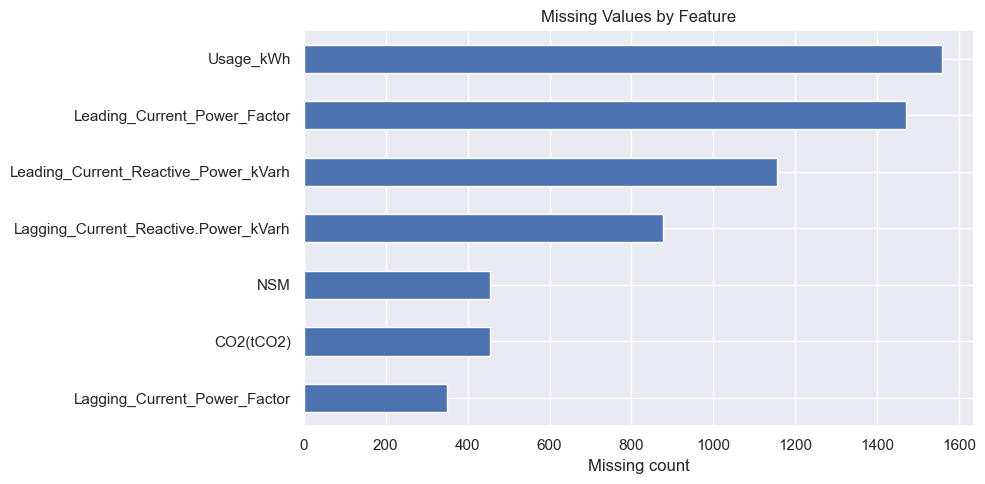

In [16]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    plt.figure(figsize=(10, 5))
    missing.sort_values().plot(kind="barh")
    plt.title("Missing Values by Feature")
    plt.xlabel("Missing count")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

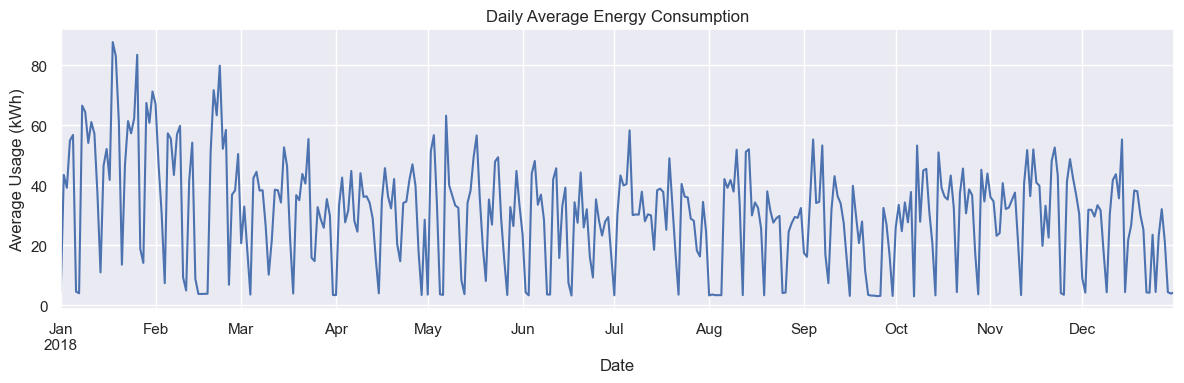

In [17]:
daily_usage = df.set_index("Date_Time")["Usage_kWh"].resample("D").mean()
plt.figure(figsize=(12, 4))
daily_usage.plot()
plt.title("Daily Average Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average Usage (kWh)")
plt.tight_layout()
plt.show()

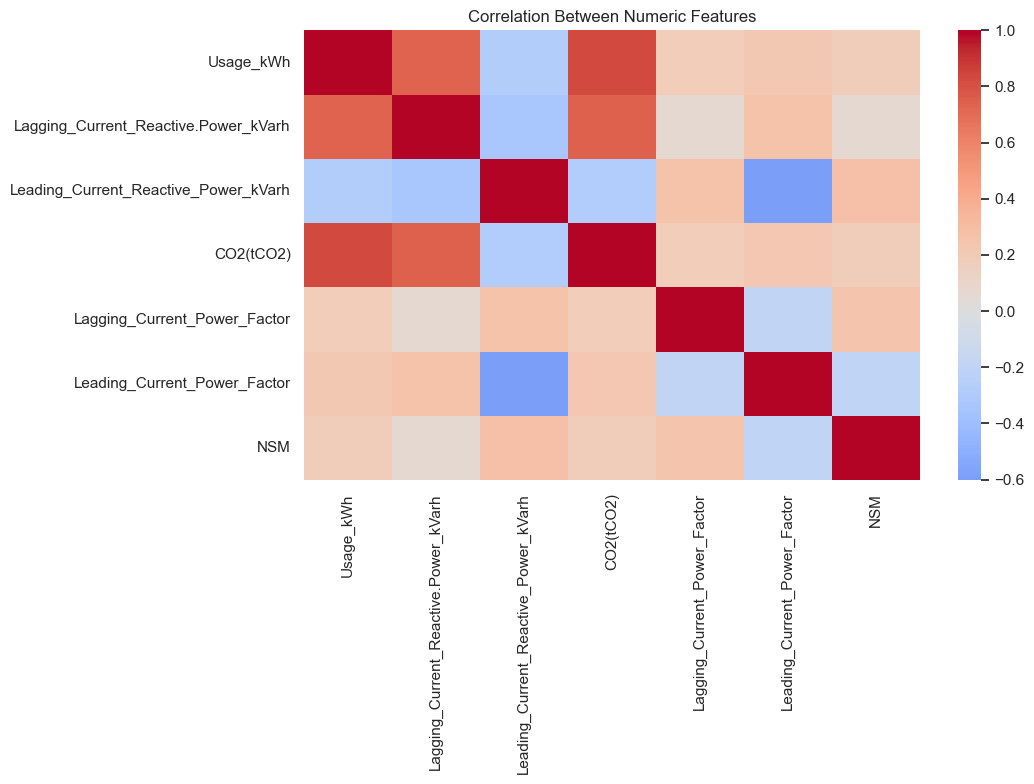

In [18]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if len(numeric_cols) > 1:
    plt.figure(figsize=(11, 8))
    sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0)
    plt.title("Correlation Between Numeric Features")
    plt.tight_layout()
    plt.show()

In [19]:
df["year"] = df["Date_Time"].dt.year
df["month"] = df["Date_Time"].dt.month
df["day"] = df["Date_Time"].dt.day
df["day_of_week"] = df["Date_Time"].dt.dayofweek
df["hour"] = df["Date_Time"].dt.hour
df["minute"] = df["Date_Time"].dt.minute

last_month = df["Date_Time"].dt.to_period("M").max()
test_mask = df["Date_Time"].dt.to_period("M") == last_month

train_df = df.loc[~test_mask].copy()
test_df = df.loc[test_mask].copy()

target = "Load_Type"
feature_cols = [c for c in df.columns if c not in [target, "Date_Time"]]

X_train, y_train = train_df[feature_cols], train_df[target]
X_test, y_test = test_df[feature_cols], test_df[target]

print("Held-out test month:", str(last_month))
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\\nTraining date range:", train_df["Date_Time"].min(), "to", train_df["Date_Time"].max())
print("Test date range:", test_df["Date_Time"].min(), "to", test_df["Date_Time"].max())
print("\\nTrain class distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Test class distribution:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Held-out test month: 2018-12
Training rows: 32064
Test rows: 2977
\nTraining date range: 2018-01-01 00:00:00 to 2018-11-30 23:45:00
Test date range: 2018-12-01 00:00:00 to 2018-12-31 23:45:00
\nTrain class distribution:


,proportion
Load_Type,
Light_Load,0.509232
Medium_Load,0.280439
Maximum_Load,0.210329


Test class distribution:


,proportion
Load_Type,
Light_Load,0.586161
Medium_Load,0.236480
Maximum_Load,0.177360


In [20]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
], remainder="drop")

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'year', 'month', 'day', 'day_of_week', 'hour', 'minute']
Categorical features: []


In [21]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, max_depth=20),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2
    )
}

results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)
    fitted_models[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Random Forest,0.9180,0.8926,0.9181,0.9018
1,Decision Tree,0.9002,0.8705,0.9223,0.8904
2,Extra Trees,0.8636,0.8217,0.8405,0.8258
3,Logistic Regression,0.5811,0.5274,0.5086,0.5027
4,Dummy baseline,0.5862,0.1954,0.3333,0.2464


Selected model: Random Forest
\nClassification report:
              precision    recall  f1-score   support

  Light_Load       0.99      0.91      0.95      1745
Maximum_Load       0.89      0.87      0.88       528
 Medium_Load       0.80      0.97      0.88       704

    accuracy                           0.92      2977
   macro avg       0.89      0.92      0.90      2977
weighted avg       0.93      0.92      0.92      2977



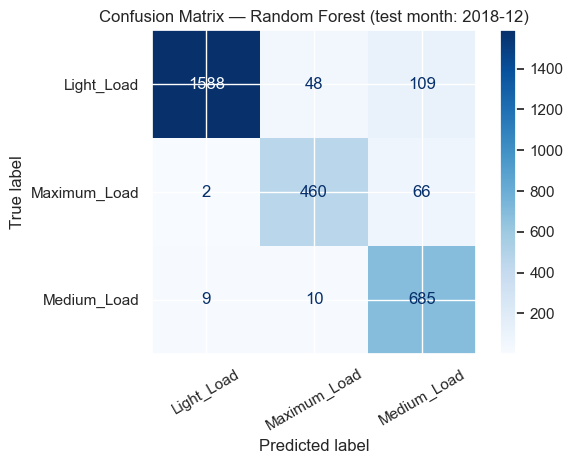

In [22]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
y_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=30, cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name} (test month: {last_month})")
plt.tight_layout()
plt.show()

,importance
numeric__NSM,0.260622
numeric__hour,0.249120
numeric__month,0.119750
numeric__Usage_kWh,0.084361
numeric__CO2(tCO2),0.061970
numeric__Lagging_Current_Power_Factor,0.060614
numeric__Lagging_Current_Reactive.Power_kVarh,0.041638
numeric__Leading_Current_Power_Factor,0.031169
numeric__Leading_Current_Reactive_Power_kVarh,0.028398
numeric__day_of_week,0.027539


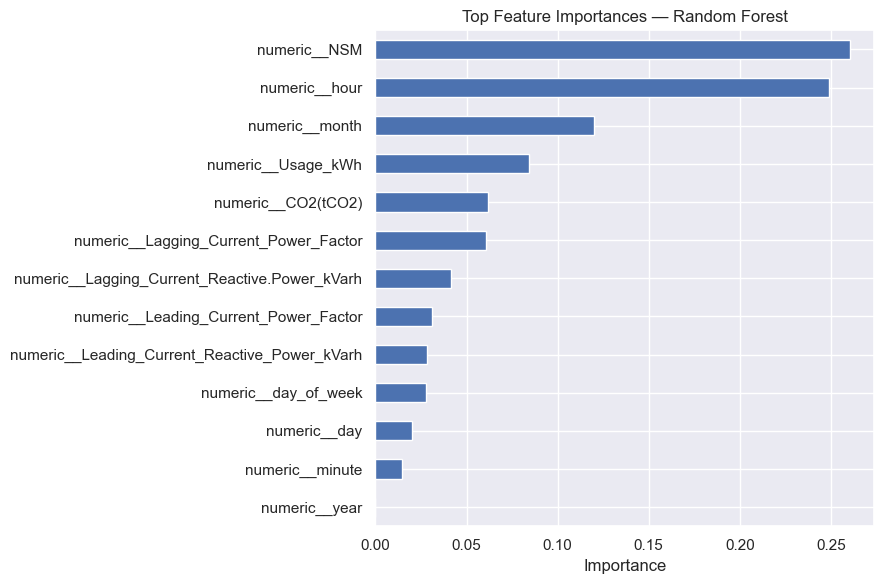

In [23]:
classifier = best_model.named_steps["classifier"]
if hasattr(classifier, "feature_importances_"):
    transformed_names = best_model.named_steps["preprocessor"].get_feature_names_out()
    importances = pd.Series(classifier.feature_importances_, index=transformed_names)
    display(importances.sort_values(ascending=False).head(15).to_frame("importance"))

    importances.sort_values().tail(15).plot(kind="barh", figsize=(9, 6))
    plt.title(f"Top Feature Importances — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("The selected model does not expose tree-based feature importances.")

In [24]:
import os

print(os.getcwd())

C:\Users\krish


In [25]:
import pandas as pd

df = pd.read_csv("load_data.csv")
display(df.head())

,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load
